In [40]:
import numpy as np
from scipy.linalg import solve_banded
import matplotlib.pyplot as plt


class FVM_HodgkinHuxley:
    def __init__(self, num_nodes, g_axial):
        self.num_nodes = num_nodes
        self.g_axial = g_axial

        # Replaces PyG's `aggr_out`: pre-calculate the sum of g_axial connected to each node.
        # Interior nodes have 2 neighbors (East & West); sealed boundaries have 1 neighbor.
        self.axial_sum = np.full(num_nodes, 2.0 * g_axial)
        self.axial_sum[0] = 1.0 * g_axial   # Left sealed boundary (no West neighbor)
        self.axial_sum[-1] = 1.0 * g_axial  # Right boundary (no East neighbor)

    ## Internal class functions to define the alpha and beta functions
    @staticmethod
    def _rate_fractional(v, A, V_shift, K, eps):
        return A * (v + V_shift) / (1.0 - np.exp(-(v + V_shift) / K) + eps)

    @staticmethod
    def _rate_exponential(v, A, V_shift, K):
        return A * np.exp(-(v + V_shift) / K)

    @staticmethod
    def _rate_inverse_sigmoid(v, A, V_shift, K):
        return A / (1.0 + np.exp(-(v + V_shift) / K))

    def step(self, V, gating_vars, p, I_ext, dt):
        # 1. Unpack the gating variables (shape: [num_nodes,])
        m, h, n = gating_vars[:, 0], gating_vars[:, 1], gating_vars[:, 2]

        # 2. Rush-Larsen exact exponential integration for m, h, n
        alpha_m = self._rate_fractional(V, *p['alpha_m'])
        beta_m  = self._rate_exponential(V, *p['beta_m'])
        m_inf = alpha_m / (alpha_m + beta_m)
        tau_m = 1.0 / (alpha_m + beta_m)
        m_new = m_inf + (m - m_inf) * np.exp(-dt / tau_m)

        alpha_h = self._rate_exponential(V, *p['alpha_h'])
        beta_h  = self._rate_inverse_sigmoid(V, *p['beta_h'])
        h_inf = alpha_h / (alpha_h + beta_h)
        tau_h = 1.0 / (alpha_h + beta_h)
        h_new = h_inf + (h - h_inf) * np.exp(-dt / tau_h)

        alpha_n = self._rate_fractional(V, *p['alpha_n'])
        beta_n  = self._rate_exponential(V, *p['beta_n'])
        n_inf = alpha_n / (alpha_n + beta_n)
        tau_n = 1.0 / (alpha_n + beta_n)
        n_new = n_inf + (n - n_inf) * np.exp(-dt / tau_n)

        gating_vars_new = np.column_stack([m_new, h_new, n_new])

        # 3. Linearized ionic current terms (Eqs. 10-14 in Ashraf et al., 2026)
        g_Na_eff = p['g_Na'] * (m_new**3) * h_new
        g_K_eff  = p['g_K']  * (n_new**4)
        g_L_eff  = p['g_L']

        g_total  = g_Na_eff + g_K_eff + g_L_eff
        I_linear = (g_Na_eff * p['E_Na'] +
                    g_K_eff  * p['E_K']  +
                    g_L_eff  * p['E_L'])

        # 4. Construct diagonal (a_P) and right-hand side vector (b_P)
        a_P = 1.0 + (dt / p['C_m']) * (self.axial_sum + g_total)
        b_P = V + (dt / p['C_m']) * (I_linear + I_ext)

        return a_P, b_P, gating_vars_new



In [41]:

## Initialize the model and parameters (modern resting convention V_rest = -65 mV)
HH_PARAMS = {
    # Tuples ordered as: (A, V_shift, K, [eps])
    'alpha_m': (0.1, 40.0, 10.0, 1e-8),
    'beta_m':  (4.0, 65.0, 18.0),
    'alpha_h': (0.07, 65.0, 20.0),
    'beta_h':  (1.0, 35.0, 10.0),
    'alpha_n': (0.01, 55.0, 10.0, 1e-8),
    'beta_n':  (0.125, 65.0, 80.0),
    'g_Na': 120.0, 'E_Na': 50.0,
    'g_K': 36.0,   'E_K': -77.0,
    'g_L': 0.3,    'E_L': -54.387,
    'C_m': 1.0
}

# Simulation parameters (matching the paper's full 800-node grid):
dt = 0.01      # ms
t_max = 40.0   # ms
steps = int(t_max / dt)

num_nodes = 800
axon_length = 1.0     # cm
dx = axon_length / num_nodes
axon_radius = 0.0238  # cm
Ri = 35.4             # ohm*cm

# Axial conductance between compartments (converted from S/cm^2 to mS/cm^2)
g_axial = (axon_radius * 1000.0) / (2.0 * Ri * dx**2)
off_diag_val = -(dt / HH_PARAMS['C_m']) * g_axial

# Initialize the solver and state arrays
FVM_HH_solver = FVM_HodgkinHuxley(num_nodes, g_axial)

V = np.full(num_nodes, -65.0)
m = np.full(num_nodes, 0.0529)
h = np.full(num_nodes, 0.5961)
n = np.full(num_nodes, 0.3177)
gating_vars = np.column_stack([m, h, n])

# Store output traces in pre-allocated 2D NumPy arrays (faster than dict lists)
history_V = np.zeros((steps, num_nodes))
history_gating_vars = np.zeros((steps, num_nodes, 3))
time_track = np.arange(steps) * dt

## Solve the model at each time step
for step in range(steps):
    t = time_track[step]
    I_ext = np.zeros(num_nodes)

    # 1. Update gating variables and compute linear system vectors
    a_P, b_P, gating_vars = FVM_HH_solver.step(V, gating_vars, HH_PARAMS, I_ext, dt)

    # 2. Pack the tridiagonal matrix in SciPy banded format (shape: [3, num_nodes])
    # Row 0: Upper diagonal (a_E, shifted right by 1)
    # Row 1: Main diagonal  (a_P)
    # Row 2: Lower diagonal (a_W, shifted left by 1)
    ab = np.zeros((3, num_nodes))
    ab[0, 1:]  = off_diag_val
    ab[1, :]   = a_P
    ab[2, :-1] = off_diag_val

    # 3. Enforce boundary & voltage-clamp conditions in the banded matrix
    # Absorbing right boundary at final node (fixed at -65.0 mV)
    ab[1, -1] = 1.0
    ab[2, -2] = 0.0  # Zero out connection from West neighbor (node N-2)
    b_P[-1]   = -65.0

    # Voltage clamp first 3 nodes to -45.0 mV (20 mV depolarization) between 1-2 ms
    if 1.0 <= t <= 2.0:
        for idx in range(3):
            ab[1, idx] = 1.0
            if idx + 1 < num_nodes:
                ab[0, idx + 1] = 0.0  # Zero out connection from East neighbor
            if idx - 1 >= 0:
                ab[2, idx - 1] = 0.0  # Zero out connection from West neighbor
            b_P[idx] = -45.0

    # 4. Solve tridiagonal system in O(N) time using Thomas algorithm (LAPACK dgtsv)
    V = solve_banded((1, 1), ab, b_P)

    # 5. Record output
    history_V[step] = V
    history_gating_vars[step] = gating_vars



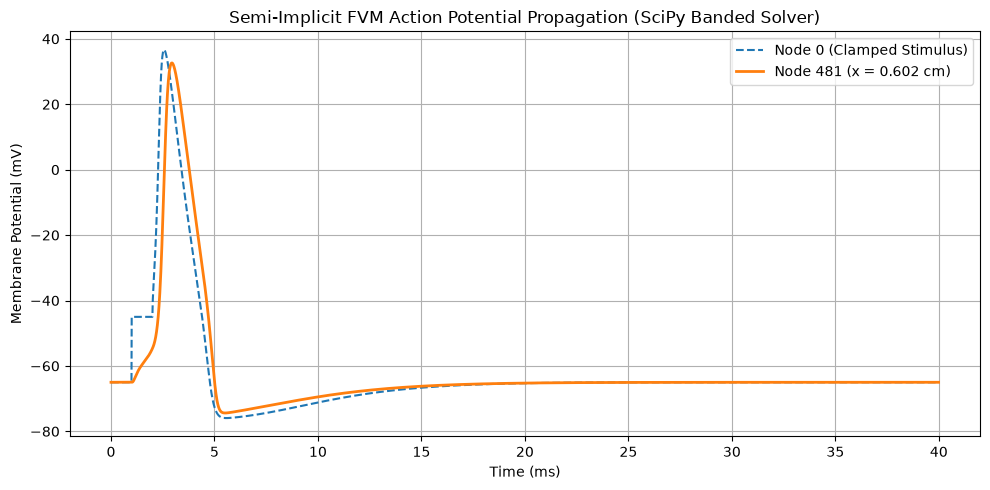

In [42]:
# Plotting Action Potential at x = 0.602 cm (Node 481, matching Fig. 3 in the paper)
probe_node = int(0.602 / dx)
plt.figure(figsize=(10, 5))
plt.plot(time_track, history_V[:, 0], label='Node 0 (Clamped Stimulus)', linestyle='--')
plt.plot(time_track, history_V[:, probe_node], label=f'Node {probe_node} (x = 0.602 cm)', linewidth=2)
plt.title("Semi-Implicit FVM Action Potential Propagation (SciPy Banded Solver)")
plt.xlabel("Time (ms)")
plt.ylabel("Membrane Potential (mV)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



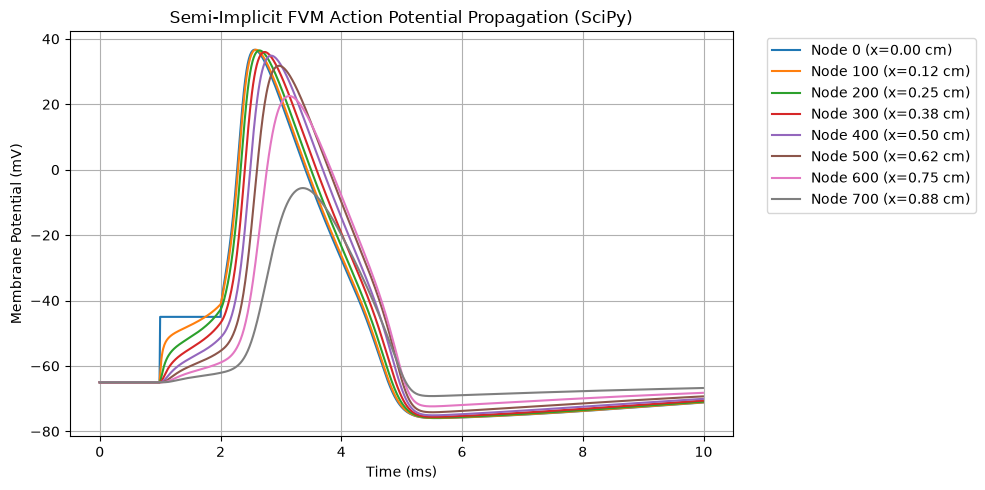

In [43]:
# Plotting Action Potential Propagation

plt.figure(figsize=(10, 5))

for node in range(0, 800, 100):
    plt.plot(time_track[0:1000], history_V[0:1000, node], label=f'Node {node} (x={node*dx:.2f} cm)')

plt.title("Semi-Implicit FVM Action Potential Propagation (SciPy)")
plt.xlabel("Time (ms)")
plt.ylabel("Membrane Potential (mV)")

# Move the large legend outside the main plot area
plt.legend(bbox_to_anchor=(1.04, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

In [44]:
## Ionic current densities

ValueError: x and y must have same first dimension, but have shapes (4000,) and (800,)

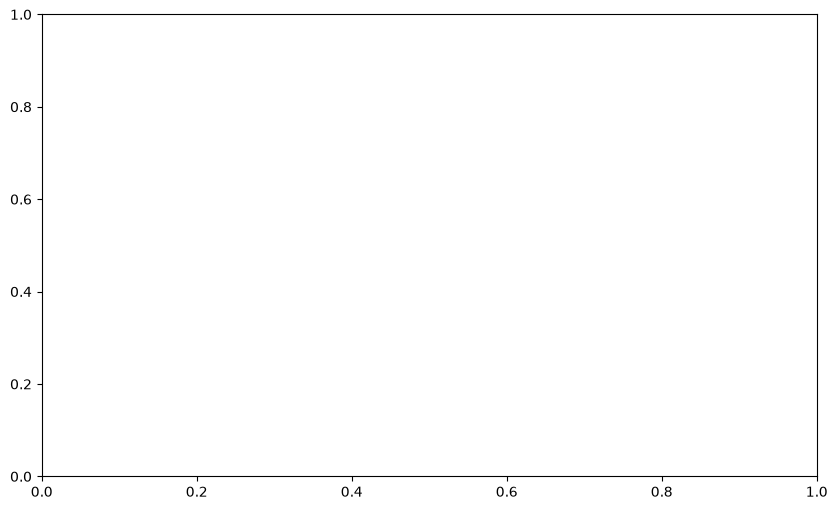

In [45]:
## Gating variables at root:


# 8. Plotting Gating Variables
# Extract m, h, and n traces specifically for Node 0
node_idx = 0
m_trace = [state[0] for state in history_gating_vars[node_idx]]
h_trace = [state[1] for state in history_gating_vars[node_idx]]
n_trace = [state[2] for state in history_gating_vars[node_idx]]

plt.figure(figsize=(10, 6))
plt.plot(time_track, m_trace, label='m (Na+ Activation)')
plt.plot(time_track, h_trace, label='h (Na+ Inactivation)')
plt.plot(time_track, n_trace, label='n (K+ Activation)')

plt.title(f"Gating Variable Dynamics (Node {node_idx})")
plt.xlabel("Time (ms)")
plt.ylabel("State / Probability (0 to 1)")
plt.legend(loc='center right')
plt.grid(True)
plt.show()


In [ ]:
## Refractory Period